# Introduction

This notebook documents the creation of my first ever machine learning model. Before I can dive deep into learning AI security, I will slowly work to generally understand the basics of ML and GenAI. I used ChatGPT's GPT 6 to walk me through the general flow of builidng a ML model along with hints that point me towards proper documentation. Otherwise, the code and documentation is written by me to better understand concepts.

Before continuing, the difference between an ML model and algorithm is vital to understand. The Ml algorithm is what the underlying mathematical procedure used to train and predict whereas the ML model is the shippable product that has been trained and thus has learned weights. 

In [12]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from ucimlrepo import fetch_ucirepo 
import joblib

## Task 1: Loading our dataset and understanding its contents

The dataset is Spambase, a collection of spam and benign emails. Note: this dataset does not contain the emails themselves rather, they include programmatically parsed versions. For example, the features show how many times certain words, characters, run-on sentences, etc. occur. All common signs of poorly crafted spam emails.  

Note: y.squeeze() was used to satisfy a DataConversionWarning about y_train not being one-dimensional later during training

In [4]:
# fetch dataset 
spambase = fetch_ucirepo(id=94) 

# Features = data points collected
# targets (aka labels) = desired result
x = spambase.data.features
y = spambase.data.targets
y = y.squeeze()

# x and y are both dataframes
print(f"Type: {type(x)}")

# isolate first emails features and its result
print(x.loc[0])
print(f"Result: {y.loc[0]}")

Type: <class 'pandas.DataFrame'>
word_freq_make                  0.000
word_freq_address               0.640
word_freq_all                   0.640
word_freq_3d                    0.000
word_freq_our                   0.320
word_freq_over                  0.000
word_freq_remove                0.000
word_freq_internet              0.000
word_freq_order                 0.000
word_freq_mail                  0.000
word_freq_receive               0.000
word_freq_will                  0.640
word_freq_people                0.000
word_freq_report                0.000
word_freq_addresses             0.000
word_freq_free                  0.320
word_freq_business              0.000
word_freq_email                 1.290
word_freq_you                   1.930
word_freq_credit                0.000
word_freq_your                  0.960
word_freq_font                  0.000
word_freq_000                   0.000
word_freq_money                 0.000
word_freq_hp                    0.000
word_freq_hpl    

## Task 2: Explore trends across the data

Using the .describe() method, we can see a general overview of the features across all emails.

The resulting table is arranged with these metrics
- count - The total number of non-null (not empty) values.
- mean - The mathematical average of the column.
- std	- The standard deviation, which measures how spread out your data is from the mean.	A high standard deviation means the data points are highly varied; a low one means they cluster tightly around the average.
- min	- The smallest value found in that column.
- 25%	- 25% of your data points fall below this value.
- 50%	- The middle value of your data. If it is significantly different from the mean, your data is likely skewed.
- 75%	- 75% of your data points fall below this value.
- max	- The largest value found in that column.


In [5]:
print(x.describe())

       word_freq_make  word_freq_address  word_freq_all  word_freq_3d  \
count     4601.000000        4601.000000    4601.000000   4601.000000   
mean         0.104553           0.213015       0.280656      0.065425   
std          0.305358           1.290575       0.504143      1.395151   
min          0.000000           0.000000       0.000000      0.000000   
25%          0.000000           0.000000       0.000000      0.000000   
50%          0.000000           0.000000       0.000000      0.000000   
75%          0.000000           0.000000       0.420000      0.000000   
max          4.540000          14.280000       5.100000     42.810000   

       word_freq_our  word_freq_over  word_freq_remove  word_freq_internet  \
count    4601.000000     4601.000000       4601.000000         4601.000000   
mean        0.312223        0.095901          0.114208            0.105295   
std         0.672513        0.273824          0.391441            0.401071   
min         0.000000        0.

## Task 3: Inspecting the quality of our data

The data is parsed for any missing data points.

In [6]:
# depicts missing values per feature in teh data set
print(x.isnull().sum())

# Both spam (1) and benign (0) emails are represented
print(y.value_counts())

word_freq_make                0
word_freq_address             0
word_freq_all                 0
word_freq_3d                  0
word_freq_our                 0
word_freq_over                0
word_freq_remove              0
word_freq_internet            0
word_freq_order               0
word_freq_mail                0
word_freq_receive             0
word_freq_will                0
word_freq_people              0
word_freq_report              0
word_freq_addresses           0
word_freq_free                0
word_freq_business            0
word_freq_email               0
word_freq_you                 0
word_freq_credit              0
word_freq_your                0
word_freq_font                0
word_freq_000                 0
word_freq_money               0
word_freq_hp                  0
word_freq_hpl                 0
word_freq_george              0
word_freq_650                 0
word_freq_lab                 0
word_freq_labs                0
word_freq_telnet              0
word_fre

## Task 4: Splitting the data

This dataset must be split into both a training and testing dataset. The model will learn from the training data, and then the model's accuracy will be gauged with the testing set. 80% of our original data will be used for training, while the remaining 20% will be used to test.

In [7]:
# return values will remain in dataframe format
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# check if split occured correctly and if the proportion of spam vs benign was kept
print(f"Dimension of our training data set: {x_train.shape}")
print(y_train.value_counts())
print(f"Dimension of our testing data set: {x_test.shape}")
print(y_test.value_counts())

Dimension of our training data set: (3680, 57)
Class
0    2257
1    1423
Name: count, dtype: int64
Dimension of our testing data set: (921, 57)
Class
0    531
1    390
Name: count, dtype: int64


## Task 5: Choosing an algorithm and scaling our data

Two vital steps occur here, first, our features are scaled such that their mean is ~0 and standard deviation is ~1. An easier way to think about the need for this step is visualizing features with drastically different values. Take for example, two features: frequency of the word 'money' = 0.2 and run-on sentence character length = 98. These are two very different numbers that algorithms (like Logistic Regression) can struggle to train on. Therefore, scaling these values towards a common metric aids the algorithm's performance.  

Next, we will initiate a 'dumb' model, one that has not yet been trained and thus its weights are meaningless. In this example, the Logistic Regression algorithm (a type of binary classifier algorithm) will be used to build this model. This algorithm learns the importance of each feature and how it contributes to the result (1 for spam, 0 for benign). This 'importance' is called a weight. The learned weights and corresponding features are multiplied and summed into a score. Logistic regression applies the sigmoid function, which squeezes this score (a real number) into a value between 0 and 1. A threshold is set (in this case 0.5) which if passed will result in a spam classification.

The use of make_pipeline acts just like a Linux command-line pipe '|'. The results of scaling are passed to Logistic Regression for further operations. 

In [8]:
pipe = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight='balanced', solver='saga', l1_ratio=0.9, max_iter=1000))

## Task 6: Training our model

We are using supervised learning (data has clear and defined labels, aka results). To train, use the built-in .fit method.

To verify if the model completed the training process, the coef_, intercept_, and classes_ variables can be inspected.

- Coef - Depicts the learned weight. One for each of the 57 features. Positive weights push the prediction to spam and vice versa.
- Intercept - The learned bias term. Used to calculate the aforementioned score.
- Classes - The result types that were identified. In this case, spam (1) or not spam (0)

In [2]:
pipe.fit(x_train, y_train)

logistic_model = pipe.named_steps["logisticregression"]

print(f"COEF: {logistic_model.coef_}")
print(f"Intercept: {logistic_model.intercept_}")
print(f"Classes: {logistic_model.classes_}")

NameError: name 'pipe' is not defined

## Task 7: Evaluating the model

Now the model is given data it has not seen before (x_test), and a prediction is generated. The prediction is then compared to the actual results (y_test), and a score is computed.

In [10]:
y_pred = pipe.predict(x_test)

score = accuracy_score(y_test, y_pred, normalize=True )
print(f"{score * 100}% of the emails were classified correctly!")

92.61672095548317% of the emails were classified correctly!


## Task 8: Inspecting the Mistakes

This run was not perfect, around 8% of emails were classified incorrectly. A confusion matrix can be created to understand where the model went astray. This matrix can be visualized below.

As seen, there were:
- 506 correctly classified non-spam emails (True Negatives).
- 341 correctly classified spam emails (True Positives).
- 49 spam emails incorrectly classified as non-spam (False Negatives).
- 25 non-spam emails incorrectly classified as spam (False Positives).

[[499  32]
 [ 36 354]]


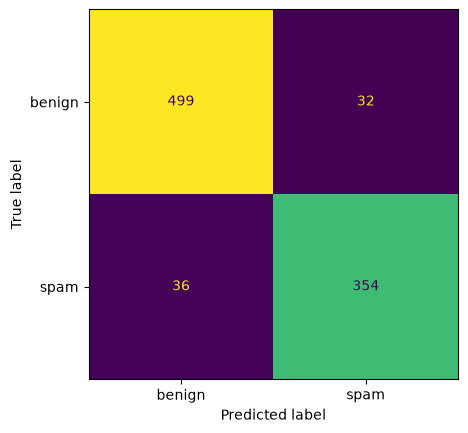

In [11]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

ConfusionMatrixDisplay.from_estimator(pipe, x_test, y_test, display_labels=['benign', 'spam'], colorbar=False)

plt.show()

## Task 9: Improvement

The first run of any model will almost never be perfect. There are numerous ways to attempt to improve the accuracy and precision of the model like investigating more data or switching algorithms. In this specific project the models settings will be tweaked to try and hone the accuracy of the classification.

When the Logistic Regression model was originally created the majority of the parameters were left to their defaults. Grid searches are used to find the optimal configuration of the model to produce the best outcome. 

These parameters, and their effects on the model, are explained below:

**Paramter C:** This is the regularization strength parameter which controls how much penalty a model receives for large/complex weights thus preventing overfitting. In simpler terms, models will sometimes have larger weights that push decisions in a specific direction based on the data it was trained on. However, this may have consequences on fresh data sets.
- Raising regularization lowers the penalty and weights can stray further from 0 to fit the training data. May result in trouble classifying new data. 
- Lowering regularization raises the penalty which keeps weights closer to 0.

**Parameter Class_Weight:** This represents how much the model cares about each class, or in our scenario, whether an email is spam or not, by telling the model how costly misclassifications are. There are two options here:
- 'None': a mistake is treated equally across classes.
- 'Balanced': the least common class receives more weight.

**Parameter Solvers:** This is simply the method the model uses to optimize its weights. The solvers used below are only a few examples of different algorithms.

**Paramter l1_ratios:** This number controls the ratio between the L1 and L2 regularization styles (and is thus closely related to C). 
- L1: Sparsity in model weights thus allowing some weights to become zero.
- L2: Shrinks weights toward zero without usually zeroing out any weights.

In [ ]:
# This custom code uses a technique called grid search to find the optimal configuration of the model by testing all values. There are builtin functions that implement grid search.

#initialize lists full over our test values or set ranges
c_reg = [0.001, 0.01, 0.09, 0.1, 0.5, 1, 5, 10, 100]
class_w = [None, "balanced"]
solvers = ["lbfgs", "liblinear", "saga"]
l1_ratios = [0.0, 0.1, 0.25, 0.5, 0.6, 0.75, 0.8, 0.9, 1.0]

best_c = None
best_class = None
best_solver = None
best_l1 = None
best_perc = 0.00

# helper that conducts the actual training
def train(c, cw, sol, l1):
    pipe = make_pipeline(StandardScaler(), LogisticRegression(C=c, l1_ratio= l1, class_weight=cw, solver=sol, max_iter=1000))
    pipe.fit(x_train, y_train)
    y_pred = pipe.predict(x_test)
    score = accuracy_score(y_test, y_pred, normalize=True )
    return (score * 100)

# iteratively, O(n^4) YIKES!, test each configuration value and save the best result
for c in c_reg:
    for cw in class_w:
        for s in solvers:
            for l1 in l1_ratios:

                if s == "lbfgs" and l1 == 0.0:
                    res = train(c, cw, s, l1)
                elif s == "liblinear" and l1 == 0.0:
                    res = train(c, cw, s, l1)
                elif s == "saga":
                    res = train(c, cw, s, l1)
                else:
                    continue
                
                if res > best_perc:
                    best_perc = res
                    best_c = c
                    best_class = cw
                    best_solver = s
                    best_l1 = l1

print(f"Best Perc={best_perc}derived from a C={best_c}, Class_weight={best_class}, Solver={best_solver}, and l1_ratio={best_l1}")

## Best Perc=92.72529858849077 derived from a C=0.1, Class_weight=balanced, Solver=saga, and l1_ratio=0.9

## Task 10: Packaging the model

The technical term for storing a trained model for post-training use is called model serialization. Using joblib allows us to persist and load our model to and from disk. Therefore, other users will be able to use the trained model for inference on their own data.

In [13]:
saved_file = joblib.dump(pipe, "spam_detector.joblib")

## Moving Forward

This simple spam classifier is now built and ready to use. Refer to the 'user.py' file to learn how a user can load the model from disk, parse emails, and put the classifier to use. 